# AI Approach's AI Bootcamp
## Machine Learning Course - Final Project: </br> Airport Traffic Prediction V2


**Done by:** Osama Al-Asadi </br>
**Course Instructor:** Eng. Anas Khodayf

### Project Overview

This project studies data colleceted on airport traffic from multiple countries in Europe from 2016 to 2026. The data also give an insight to how different seasons influence the air traffic, and when to expect increased demand on airports.

### Dataset Analysed
The origninal chosen dataset was "Airport Traffic Dataset" for 2025 by Nilesh Kadam obtained from Kaggle.com, then using the source of the data, https://ansperformance.eu/csv/, I downloaded the rest of the data for the years 2016 to 2026.  According to the dataset owner, the dataset provides a detailed daily breakdown of air traffic movements for various international airports. It contains daily flight traffic data for the full year of 2025. It tracks scheduled and actual arrivals and departures across a global network of airports, categorized by ICAO codes and state names. 
The dataset contains 10 columns: 
* YEAR: The calendar year of the record.
* MONTH_NUM: The numerical month (1-12).
* MONTH_MON: The 3-letter abbreviation of the month.
* FLT_DATE: The specific date of the traffic measurement.
* APT_ICAO: The 4-letter International Civil Aviation Organization airport code.
* APT_NAME: The official name of the airport.
* STATE_NAME: The country or administrative state where the airport is located.
* FLT_DEPT_1: Total number of flight departures for the day.
* FLT_ARR_1: Total number of flight arrivals for the day.
* FLT_TOT_1: Total daily flight movements (Arrivals + Departures).

In a previous training trial it was concluded that the features in this dataset are not sufficient to create a reliable model; therefore, additional features were imported from another dataset, obtained from ourairports.com - airports.csv. The dataset composes of extinsive information about numurous local and internaltional airports around the world. The new features chosen from the dataset are:
* Longtitude degree
* Latitude degree
* Elevation in ft

### 1. Import Libraries and Read Dataset

In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
import xgboost as xgb
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

# Read the first CSV file for the main dataset
df = pd.read_csv("datasets/airport_traffic_2016.csv")

# Read the remaining CSV files and concatenate them into a single DataFrame
for i in range(17, 27):
    df_temp = pd.read_csv(f"datasets/airport_traffic_20{i}.csv")
    df = pd.concat([df, df_temp], ignore_index=True, axis=0)

# Display the dataset head
df.head()

,YEAR,MONTH_NUM,MONTH_MON,FLT_DATE,APT_ICAO,APT_NAME,STATE_NAME,FLT_DEP_1,FLT_ARR_1,FLT_TOT_1,FLT_DEP_IFR_2,FLT_ARR_IFR_2,FLT_TOT_IFR_2
0,2016,1,JAN,2016-01-01,LATI,Tirana,Albania,24,27,51,NaN,NaN,NaN
1,2016,1,JAN,2016-01-01,UDYZ,Yerevan,Armenia,8,15,23,NaN,NaN,NaN
2,2016,1,JAN,2016-01-01,LOWG,Graz,Austria,6,7,13,NaN,NaN,NaN
3,2016,1,JAN,2016-01-01,LOWI,Innsbruck,Austria,26,32,58,NaN,NaN,NaN
4,2016,1,JAN,2016-01-01,LOWK,Klagenfurt,Austria,3,4,7,NaN,NaN,NaN


In [2]:
# Display the dataset tail, unsure that the data is complete
df.tail()

,YEAR,MONTH_NUM,MONTH_MON,FLT_DATE,APT_ICAO,APT_NAME,STATE_NAME,FLT_DEP_1,FLT_ARR_1,FLT_TOT_1,FLT_DEP_IFR_2,FLT_ARR_IFR_2,FLT_TOT_IFR_2
1213097,2026,9,SEP,2026-09-30,EGNX,East Midlands,United Kingdom,98,96,194,NaN,NaN,NaN
1213098,2026,9,SEP,2026-09-30,EGPD,Aberdeen,United Kingdom,55,53,108,NaN,NaN,NaN
1213099,2026,9,SEP,2026-09-30,EGPF,Glasgow,United Kingdom,119,127,246,NaN,NaN,NaN
1213100,2026,9,SEP,2026-09-30,EGPH,Edinburgh,United Kingdom,196,202,398,196.0,202.0,398.0
1213101,2026,9,SEP,2026-09-30,EGSS,London - Stansted,United Kingdom,304,310,614,301.0,296.0,597.0


In [3]:
# Import the additional dataset used for the extra features
apt_info = pd.read_csv("datasets/airports.csv")
apt_info.head()

,id,ident,type,name,latitude_deg,longitude_deg,elevation_ft,continent,iso_country,iso_region,municipality,scheduled_service,icao_code,iata_code,gps_code,local_code,home_link,wikipedia_link,keywords
0,6523,00A,heliport,Total RF Heliport,40.070985,-74.933689,11.0,NaN,US,US-PA,Bensalem,no,NaN,NaN,K00A,00A,https://www.penndot.pa.gov/TravelInPA/airports...,NaN,NaN
1,323361,00AA,small_airport,Aero B Ranch Airport,38.704022,-101.473911,3435.0,NaN,US,US-KS,Leoti,no,NaN,NaN,00AA,00AA,NaN,NaN,NaN
2,6524,00AK,small_airport,Lowell Field,59.947733,-151.692524,450.0,NaN,US,US-AK,Anchor Point,no,NaN,NaN,00AK,00AK,NaN,NaN,NaN
3,6525,00AL,small_airport,Epps Airpark,34.864799,-86.770302,820.0,NaN,US,US-AL,Harvest,no,NaN,NaN,00AL,00AL,NaN,NaN,NaN
4,506791,00AN,small_airport,Katmai Lodge Airport,59.093287,-156.456699,80.0,NaN,US,US-AK,King Salmon,no,NaN,NaN,00AN,00AN,NaN,NaN,NaN


### 2. Clean and Prepare the datasets

#### 2.1. Clean null ICAO code values from the new dataset

In [4]:
# Check for null values in apt_info ICAO codes column
apt_info['icao_code'].isnull().sum()

np.int64(75704)

In [5]:
# Drop rows with null ICAO codes and set the index to 'icao_code'
apt_info.dropna(subset=['icao_code'], inplace=True)
apt_info.set_index('icao_code', inplace=True)
apt_info.head()

,id,ident,type,name,latitude_deg,longitude_deg,elevation_ft,continent,iso_country,iso_region,municipality,scheduled_service,iata_code,gps_code,local_code,home_link,wikipedia_link,keywords
icao_code,,,,,,,,,,,,,,,,,,
PPIT,7977,16A,small_airport,Nunapitchuk Airport,60.905591,-162.440454,12.0,NaN,US,US-AK,Nunapitchuk,yes,NUP,PPIT,16A,NaN,https://en.wikipedia.org/wiki/Nunapitchuk_Airport,NaN
PAKA,14173,7KA,small_airport,Tatitlek Airport,60.871449,-146.690297,62.0,NaN,US,US-AK,Tatitlek,yes,TEK,PAKA,7KA,NaN,https://en.wikipedia.org/wiki/Tatitlek_Airport,AK47
PACH,15640,9A3,small_airport,Chuathbaluk Airport,61.579102,-159.216003,244.0,NaN,US,US-AK,Chuathbaluk,yes,CHU,PACH,9A3,NaN,https://en.wikipedia.org/wiki/Chuathbaluk_Airport,NaN
HCAD,324756,AAD,small_airport,Adado Airport,6.095802,46.637500,1001.0,AF,SO,SO-GA,Adado,no,AAD,HCAD,NaN,NaN,https://en.wikipedia.org/wiki/Adado_Airport,Cadaado Airport
OEBT,42257,AE-0001,small_airport,Batha Airport,24.214693,51.449890,257.0,AS,SA,SA-04,Batha,yes,NaN,OEBT,NaN,NaN,NaN,"Ras Sumeira UAE,"


In [6]:
# Keep only the columns relevant to the project
apt_info = apt_info[['latitude_deg', 'longitude_deg', 'elevation_ft']]
apt_info.head()

,latitude_deg,longitude_deg,elevation_ft
icao_code,,,
PPIT,60.905591,-162.440454,12.0
PAKA,60.871449,-146.690297,62.0
PACH,61.579102,-159.216003,244.0
HCAD,6.095802,46.637500,1001.0
OEBT,24.214693,51.449890,257.0


#### 2.2. Clean and prepare the main dataset

In [7]:
# Drop unnecessary columns (reason of dropping is in the data analysis project)
df = df.drop(['FLT_DEP_IFR_2', 'FLT_ARR_IFR_2', 'FLT_TOT_IFR_2'], axis=1)

Change the date to suitable format

In [8]:
df['FLT_DATE'] = pd.to_datetime(df['FLT_DATE'])
df.insert(3 ,'DAY_NAME', df['FLT_DATE'].dt.day_name())
df.insert(3 ,'DAY', df['FLT_DATE'].dt.day)
df.insert(3 ,'WEEKDAY', (df['FLT_DATE'].dt.dayofweek +2) % 7)
df.head()

,YEAR,MONTH_NUM,MONTH_MON,WEEKDAY,DAY,DAY_NAME,FLT_DATE,APT_ICAO,APT_NAME,STATE_NAME,FLT_DEP_1,FLT_ARR_1,FLT_TOT_1
0,2016,1,JAN,6,1,Friday,2016-01-01,LATI,Tirana,Albania,24,27,51
1,2016,1,JAN,6,1,Friday,2016-01-01,UDYZ,Yerevan,Armenia,8,15,23
2,2016,1,JAN,6,1,Friday,2016-01-01,LOWG,Graz,Austria,6,7,13
3,2016,1,JAN,6,1,Friday,2016-01-01,LOWI,Innsbruck,Austria,26,32,58
4,2016,1,JAN,6,1,Friday,2016-01-01,LOWK,Klagenfurt,Austria,3,4,7


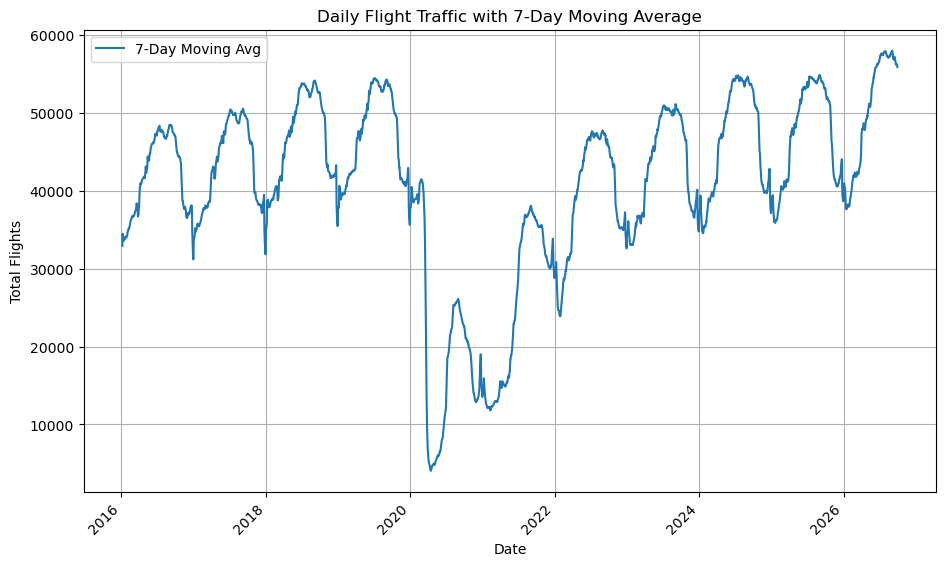

In [9]:
daily_total = df.groupby('FLT_DATE')['FLT_TOT_1'].sum().reset_index()
daily_total['ROLLING_7'] = daily_total['FLT_TOT_1'].rolling(7).mean()

plt.figure(figsize=(11, 6))

sns.lineplot(data=daily_total, x='FLT_DATE', y='ROLLING_7', label='7-Day Moving Avg')

plt.xticks(rotation=45, ha='right')
plt.title('Daily Flight Traffic with 7-Day Moving Average')
plt.xlabel('Date')
plt.ylabel('Total Flights')
plt.grid(True)

plt.show()

In [ ]:
df = df.drop(df[df["YEAR"].isin([2020, 2021, 2022])].index)
df.info()

In [ ]:
daily_total = df.groupby('FLT_DATE')['FLT_TOT_1'].sum().reset_index()
daily_total['ROLLING_7'] = daily_total['FLT_TOT_1'].rolling(7).mean()

plt.figure(figsize=(11, 6))

sns.lineplot(data=daily_total, x='FLT_DATE', y='ROLLING_7', label='7-Day Moving Avg')

plt.xticks(rotation=45, ha='right')
plt.title('Daily Flight Traffic with 7-Day Moving Average')
plt.xlabel('Date')
plt.ylabel('Total Flights')
plt.grid(True)

plt.show()

Insert the new features to the main dataframe

In [10]:
df.insert(loc=8, column="LONGITUDE", value=df["APT_ICAO"].map(apt_info["longitude_deg"]))
df.insert(loc=8, column="LATITUDE", value=df["APT_ICAO"].map(apt_info["latitude_deg"]))
df.insert(loc=8, column="ELEVATION", value=df["APT_ICAO"].map(apt_info["elevation_ft"]))
df.head()

,YEAR,MONTH_NUM,MONTH_MON,WEEKDAY,DAY,DAY_NAME,FLT_DATE,APT_ICAO,ELEVATION,LATITUDE,LONGITUDE,APT_NAME,STATE_NAME,FLT_DEP_1,FLT_ARR_1,FLT_TOT_1
0,2016,1,JAN,6,1,Friday,2016-01-01,LATI,126.0,41.414700,19.720600,Tirana,Albania,24,27,51
1,2016,1,JAN,6,1,Friday,2016-01-01,UDYZ,2838.0,40.148941,44.397887,Yerevan,Armenia,8,15,23
2,2016,1,JAN,6,1,Friday,2016-01-01,LOWG,1115.0,46.991100,15.439600,Graz,Austria,6,7,13
3,2016,1,JAN,6,1,Friday,2016-01-01,LOWI,1907.0,47.260201,11.344000,Innsbruck,Austria,26,32,58
4,2016,1,JAN,6,1,Friday,2016-01-01,LOWK,1472.0,46.642502,14.337700,Klagenfurt,Austria,3,4,7


In [ ]:
df.info()

In [ ]:
# Check for null values
df.isnull().sum()

In [ ]:
# Get a unique list of ICAO codes with missing elevation
null_icao_list = df[df["ELEVATION"].isnull()]["APT_ICAO"].unique().tolist()

print(null_icao_list)

Missing data collected using Google AI

| ICAO Code | Latitude (Deg) | Longitude (Deg) | Elevation (ft) |
| :--- | :--- | :--- | :--- |
| **EDDT** | 52.5597° N | 13.2877° E | 122 ft |
| **LELL** | 41.5209° N | 2.1051° E | 485 ft |
| **LESJ** | 39.5517° N | 2.7388° E | 27 ft |
| **LEIZ** | 38.5147° N | 3.3625° W | 2,753 ft |
| **LERE** | 39.4747° N | 1.0344° W | 2,340 ft |
| **ENVR** | 67.6546° N | 12.7273° E | 12 ft |
| **LPMT** | 38.7093° N | 9.0337° W | 46 ft |
| **EVJA** | 56.9420° N | 23.2200° E | 234 ft |
| **EICM** | 53.3002° N | 8.9416° W | 81 ft |


Add the missing rows to the dataset

In [ ]:
airport_data = {
    'icao_code': ['EDDT', 'LELL', 'LESJ', 'LEIZ', 'LERE', 'ENVR', 'LPMT', 'EVJA', 'EICM'],
    'latitude_deg': [52.5597, 41.5209, 39.5517, 38.5147, 39.4747, 67.6546, 38.7093, 56.9420, 53.3002],
    'longitude_deg': [13.2877, 2.1051, 2.7388, -3.3625, -1.0344, 12.7273, -9.0337, 23.2200, -8.9416],
    'elevation_ft': [122, 485, 27, 2753, 2340, 12, 46, 234, 81]
}

df_new_data = pd.DataFrame(airport_data).set_index('icao_code')

apt_info = pd.concat([apt_info, df_new_data], axis=0)


In [11]:
# Ensure data is inserted correctly
apt_info.tail(10)

,latitude_deg,longitude_deg,elevation_ft
icao_code,,,
ZYSQ,44.931143,124.552121,459.0
ZYTL,38.965719,121.538477,107.0
ZYTN,42.048435,125.733963,1347.0
ZYTX,41.639800,123.483668,198.0
ZYXC,40.580328,120.700374,30.0
ZYYC,47.717936,128.830519,798.0
ZYYJ,42.882801,129.451004,624.0
ZYYK,40.542524,122.358600,NaN
ZYYY,41.784354,123.496308,157.0


Updata the main dataframe with the new values

In [ ]:
df.drop(["LONGITUDE", "LATITUDE", "ELEVATION"], axis=1, inplace=True)
df.insert(loc=8, column="LONGITUDE", value=df["APT_ICAO"].map(apt_info["longitude_deg"]))
df.insert(loc=8, column="LATITUDE", value=df["APT_ICAO"].map(apt_info["latitude_deg"]))
df.insert(loc=8, column="ELEVATION", value=df["APT_ICAO"].map(apt_info["elevation_ft"]))
df.head()

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1213102 entries, 0 to 1213101
Data columns (total 16 columns):
 #   Column      Non-Null Count    Dtype         
---  ------      --------------    -----         
 0   YEAR        1213102 non-null  int64         
 1   MONTH_NUM   1213102 non-null  int64         
 2   MONTH_MON   1213102 non-null  object        
 3   WEEKDAY     1213102 non-null  int64         
 4   DAY         1213102 non-null  int32         
 5   DAY_NAME    1213102 non-null  object        
 6   FLT_DATE    1213102 non-null  datetime64[ns]
 7   APT_ICAO    1213102 non-null  object        
 8   ELEVATION   1199916 non-null  float64       
 9   LATITUDE    1199916 non-null  float64       
 10  LONGITUDE   1199916 non-null  float64       
 11  APT_NAME    1213102 non-null  object        
 12  STATE_NAME  1213102 non-null  object        
 13  FLT_DEP_1   1213102 non-null  int64         
 14  FLT_ARR_1   1213102 non-null  int64         
 15  FLT_TOT_1   1213102 non-null  in

In [13]:
df.isnull().sum()

YEAR              0
MONTH_NUM         0
MONTH_MON         0
WEEKDAY           0
DAY               0
DAY_NAME          0
FLT_DATE          0
APT_ICAO          0
ELEVATION     13186
LATITUDE      13186
LONGITUDE     13186
APT_NAME          0
STATE_NAME        0
FLT_DEP_1         0
FLT_ARR_1         0
FLT_TOT_1         0
dtype: int64

In [14]:
df.drop(['MONTH_MON', 'DAY_NAME',
         'FLT_DATE', 'APT_ICAO', 
         'APT_NAME', 'FLT_DEP_1', 
         'FLT_ARR_1'], axis=1, inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1213102 entries, 0 to 1213101
Data columns (total 9 columns):
 #   Column      Non-Null Count    Dtype  
---  ------      --------------    -----  
 0   YEAR        1213102 non-null  int64  
 1   MONTH_NUM   1213102 non-null  int64  
 2   WEEKDAY     1213102 non-null  int64  
 3   DAY         1213102 non-null  int32  
 4   ELEVATION   1199916 non-null  float64
 5   LATITUDE    1199916 non-null  float64
 6   LONGITUDE   1199916 non-null  float64
 7   STATE_NAME  1213102 non-null  object 
 8   FLT_TOT_1   1213102 non-null  int64  
dtypes: float64(3), int32(1), int64(4), object(1)
memory usage: 78.7+ MB


Map state names to indexes

In [15]:
temp = (
    df.groupby('STATE_NAME')['FLT_TOT_1']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

mapping = {}

for i in range(len(temp)):
    mapping.update({temp.iloc[i]['STATE_NAME']: i})


print(mapping)

df['STATE_NAME'] = df['STATE_NAME'].map(mapping)

{'Spain': 0, 'United Kingdom': 1, 'Germany': 2, 'France': 3, 'Italy': 4, 'Türkiye': 5, 'Norway': 6, 'Greece': 7, 'Netherlands': 8, 'Portugal': 9, 'Poland': 10, 'Switzerland': 11, 'Belgium': 12, 'Austria': 13, 'Sweden': 14, 'Ireland': 15, 'Denmark': 16, 'Finland': 17, 'Morocco': 18, 'Czech Republic': 19, 'Romania': 20, 'Hungary': 21, 'Israel': 22, 'Cyprus': 23, 'Serbia': 24, 'Luxembourg': 25, 'Latvia': 26, 'Bulgaria': 27, 'Lithuania': 28, 'Malta': 29, 'Ukraine': 30, 'Croatia': 31, 'Albania': 32, 'Georgia': 33, 'Estonia': 34, 'Armenia': 35, 'Moldova': 36, 'Slovenia': 37, 'Slovakia': 38, 'Republic of North Macedonia': 39, 'Iceland': 40, 'Bosnia and Herzegovina': 41, 'Montenegro': 42}


In [ ]:
df.plot(kind="scatter", x="LONGITUDE", y="LATITUDE", alpha=1,
             s=df["FLT_TOT_1"]/30, label="Total Flights", figsize=(10,7),
             c="ELEVATION", cmap=plt.get_cmap("jet"), colorbar=True)
plt.legend()

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1213102 entries, 0 to 1213101
Data columns (total 9 columns):
 #   Column      Non-Null Count    Dtype  
---  ------      --------------    -----  
 0   YEAR        1213102 non-null  int64  
 1   MONTH_NUM   1213102 non-null  int64  
 2   WEEKDAY     1213102 non-null  int64  
 3   DAY         1213102 non-null  int32  
 4   ELEVATION   1199916 non-null  float64
 5   LATITUDE    1199916 non-null  float64
 6   LONGITUDE   1199916 non-null  float64
 7   STATE_NAME  1213102 non-null  int64  
 8   FLT_TOT_1   1213102 non-null  int64  
dtypes: float64(3), int32(1), int64(5)
memory usage: 78.7 MB


In [17]:
df.to_csv('datasets/combined_including_2020-2022_with_nulls.csv')

### Training Models

In [ ]:
# Preprocessing Pipeline
x = df.drop(['FLT_TOT_1'], axis=1)
y = df['FLT_TOT_1']

In [ ]:
x.shape

In [ ]:
y.shape

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

XGBoost Model

In [ ]:
# xgb_model = Pipeline(steps=[
#     ('regressor', xgb.XGBRegressor(
#     objective='reg:squarederror',
#     n_estimators=3000,
#     learning_rate=0.05,
#     max_depth=5,
#     subsample=0.8,
#     colsample_bytree=0.8,
#     min_child_weight=3,
#     gamma=0.1,
#     reg_alpha=0.05,
#     reg_lambda=1,
#     early_stopping_rounds=50,
#     random_state=42
# ))
# ])

# xgb_model = Pipeline(steps=[
#     ('regressor', xgb.XGBRegressor(
#     objective='reg:squarederror',
#     n_estimators=3000,
#     learning_rate=0.1,
#     max_depth=5,
#     subsample=0.8,
#     colsample_bytree=0.6,
#     min_child_weight=10,
#     gamma=0.5,
#     reg_alpha=0.1,
#     reg_lambda=10,
#     early_stopping_rounds=50,
#     random_state=42
# ))
# ])

xgb_model = Pipeline(steps=[
    ('regressor', xgb.XGBRegressor(
    objective='reg:squarederror',
    n_estimators=3250,
    learning_rate=0.09345130495773961,
    max_depth=8,
    subsample=0.9848348894944928,
    colsample_bytree=0.6627564120404217,
    min_child_weight=9.439574346445202,
    gamma=0.38102029226599476,
    reg_alpha=0.0059313599732688845,
    reg_lambda=6.313235266795839,
    early_stopping_rounds=50,
    random_state=42
))
])

In [ ]:
xgb_model.fit(x_train, y_train,
          regressor__eval_set=[(x_test, y_test)], 
          regressor__verbose=False)

In [ ]:
# Evaluate Model
train_pred = xgb_model.predict(x_train)
test_pred = xgb_model.predict(x_test)

In [ ]:
train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

In [ ]:
print(f"\nModel Performance:")
print(f"Train RMSE: {train_rmse:.2f}")
print(f"Test RMSE: {test_rmse:.2f}")

In [ ]:
# Predict on test set
xgb_pred = xgb_model.predict(x_test)

# Calculate regression metrics
mae = mean_absolute_error(y_test, xgb_pred)
rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
r2 = r2_score(y_test, xgb_pred)

# Print metrics
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.2f}")  # Closer to 1 means better fit

In [ ]:
# Visual predictions
plt.figure(figsize=(10, 6))
plt.scatter(y_test, test_pred, alpha=0.3)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Total Flights")
plt.show()


In [ ]:
# Get feature importance scores
feature_importance = xgb_model.named_steps['regressor'].feature_importances_

# Create DataFrame
feature_importance_df = pd.DataFrame({'Feature': x_train.columns, 'Importance': feature_importance})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Display table
print(feature_importance_df)


In [ ]:
# Plot feature importance
plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importance_df['Importance'], y=feature_importance_df['Feature'], palette='crest')
plt.title("Feature Importance in XGBoost Model")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()


In [ ]:
# save xgboost model 
joblib.dump(xgb_model, "models/xgboost_airport_model_v5.pkl")

LightGBM

In [ ]:
parameters = {
    'boosting_type': 'gbdt',
    'objective': 'regression',
    'metric': ['l1', 'l2'],
    'learning_rate': 0.1,  
    'feature_fraction': 0.9,  
    'bagging_fraction': 0.7, 
    'bagging_freq': 10,  
    'max_depth': 5, 
    'num_leaves': 50,  
    'max_bin': 212,
    'num_iterations': 500,
    'min_gain_to_split': 0, 
    'min_child_weight': 1,
    'subsample': 0.8,
    'reg_lambda': 5,
    'colsample_bytree': 1.0,
    'reg_alpha': 1,
    'n_estimators': 3000,
    'verbose': -1  
}

In [ ]:
lgbm_model = LGBMRegressor(**parameters)

In [ ]:
lgbm_model.fit(x_train, y_train)

In [ ]:
lgbm_pred = lgbm_model.predict(x_test)

In [ ]:
def evaluate_model(model_name, y_test, y_pred):
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    print(f"{model_name} Performance:")
    print(f"Mean Absolute Error (MAE): {mae:.2f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
    print(f"R² Score: {r2:.4f}")
    print("-" * 50)

xgboost_v1 = joblib.load("models/xgboost_airport_model.pkl")
xgb_pred_v1 = xgboost_v1.predict(x_test)

xgboost_v2 = joblib.load("models/xgboost_airport_model_v2.pkl")
xgb_pred_v2 = xgboost_v2.predict(x_test)

xgboost_v3 = joblib.load("models/xgboost_airport_model_v3.pkl")
xgb_pred_v3 = xgboost_v3.predict(x_test)

xgboost_v4 = joblib.load("models/xgboost_airport_model_v4.pkl")
xgb_pred_v4 = xgboost_v4.predict(x_test)

xgboost_v5 = joblib.load("models/xgboost_airport_model_v5.pkl")
xgb_pred_v5 = xgboost_v5.predict(x_test)

lgbm = joblib.load("models/LightGBM_airport_model.pkl")
lgbm_pred = lgbm.predict(x_test)

evaluate_model("XGBoost with nulls", y_test, xgb_pred_v1)
evaluate_model("XGBoost no nulls 2020-2022 included", y_test, xgb_pred_v2)
evaluate_model("XGBoost no nulls 2020-2022 excluded", y_test, xgb_pred_v3)
evaluate_model("XGBoost hyperparameters", y_test, xgb_pred_v4)
evaluate_model("XGBoost optuna", y_test, xgb_pred_v5)
evaluate_model("LightGBM", y_test, lgbm_pred)

NameError: name 'x_test' is not defined

In [ ]:
df.to_csv("datasets/cleaned_airports.csv")

In [ ]:
# from sklearn.model_selection import RandomizedSearchCV

# base_pipeline = Pipeline(steps=[
#     ('regressor', LGBMRegressor(objective='regression',n_jobs=-1 , random_state=42))
# ])

# param_dist = {
#     'regressor__n_estimators': [1000, 3000, 5000],
#     'regressor__learning_rate': [0.01, 0.05, 0.1],
#     'regressor__max_depth': [3, 4, 5, 6],
#     'regressor__subsample': [0.6, 0.8, 1.0],
#     'regressor__colsample_bytree': [0.6, 0.8, 1.0],
#     'regressor__min_child_weight': [1, 5, 10],
#     'regressor__min_gain_to_split': [0, 0.1, 0.5, 1],
#     'regressor__reg_alpha': [0, 0.1, 0.5, 1],
#     'regressor__reg_lambda': [1, 5, 10]
# }

# random_search = RandomizedSearchCV(
#     estimator=base_pipeline,
#     param_distributions=param_dist,
#     n_iter=15,
#     scoring='neg_root_mean_squared_error',
#     cv=2,
#     verbose=1,
#     random_state=42,
#     n_jobs=-1
# )

# random_search.fit(
#     x_train, y_train,
#     regressor__eval_set=[(x_test, y_test)],
# )

# print(random_search.best_params_)
# print(-random_search.best_score_)

In [ ]:
# save LightGBM model 
joblib.dump(lgbm_model, "LightGBM_airport_model.pkl")

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'regressor__n_estimators': [1000, 3000, 5000],
    'regressor__learning_rate': [0.01, 0.05, 0.1],
    'regressor__max_depth': [3, 4, 5, 6],
    'regressor__subsample': [0.6, 0.8, 1.0],
    'regressor__colsample_bytree': [0.6, 0.8, 1.0],
    'regressor__min_child_weight': [1, 5, 10],
    'regressor__gamma': [0, 0.1, 0.5, 1],
    'regressor__reg_alpha': [0, 0.1, 0.5, 1],
    'regressor__reg_lambda': [1, 5, 10]
}

random_search = RandomizedSearchCV(
    xgb_model,
    param_distributions=param_dist,
    n_iter=8,
    scoring='neg_root_mean_squared_error',
    cv=2,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search.fit(
    x_train, y_train,
    regressor__eval_set=[(x_test, y_test)],
    regressor__verbose=False
)

print(random_search.best_params_)
print(-random_search.best_score_)


In [ ]:

# ============================================================
# OPTIMIZED XGBOOST REGRESSION WITH OPTUNA
# Designed for 100K - 1M rows
# Compatible with older NVIDIA GPUs by using CPU training
# ============================================================

# Install if necessary:
# pip install -U xgboost optuna scikit-learn packaging

import optuna
import joblib
import warnings

from packaging.version import Version
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_val_score

warnings.filterwarnings("ignore")

optuna.logging.set_verbosity(optuna.logging.WARNING)


# ============================================================
# 1. CONFIGURATION
# ============================================================

RANDOM_STATE = 42

N_TRIALS = 60

N_SPLITS = 3

N_JOBS = -1

XGB_VERSION = Version(xgb.__version__)

print("=" * 60)
print("XGBOOST OPTIMIZATION")
print("=" * 60)

print("XGBoost version:", xgb.__version__)

print("Dataset rows:", len(x_train))
print("Dataset features:", x_train.shape[1])

print("Optimization trials:", N_TRIALS)
print("Cross-validation folds:", N_SPLITS)


# ============================================================
# 2. HARDWARE CONFIGURATION
# ============================================================

# Your GeForce 840M is not compatible with the current
# installed XGBoost CUDA binary.
#
# CPU histogram training is the reliable configuration.

hardware_params = {
    "tree_method": "hist",
    "device": "cpu"
}

print("\nTraining device: CPU")
print("Tree method: histogram")


# ============================================================
# 3. CROSS VALIDATION
# ============================================================

cv = KFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)


# ============================================================
# 4. OPTUNA OBJECTIVE FUNCTION
# ============================================================

def objective(trial):

    params = {

        "n_estimators": trial.suggest_int(
            "n_estimators", 1000, 4000, step=250
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.005, 0.15, log=True
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 3, 8
        ),

        "min_child_weight": trial.suggest_float(
            "min_child_weight", 1, 20, log=True
        ),

        "subsample": trial.suggest_float(
            "subsample", 0.65, 1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.5, 1.0
        ),

        "gamma": trial.suggest_float(
            "gamma", 0.0, 5.0
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-4, 10.0, log=True
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda", 0.1, 20.0, log=True
        ),

        "max_bin": 128,
        "tree_method": "hist",
        "device": "cpu",
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        "random_state": 42,
        "n_jobs": -1,
        "verbosity": 0
    }

    cv = KFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    fold_scores = []

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(x_train)
    ):

        X_fold_train = x_train.iloc[train_idx]
        X_fold_val = x_train.iloc[val_idx]

        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        # Create fresh model
        model = clone(xgboost_v4)

        model_params = {
            f"regressor__{key}": value
            for key, value in params.items()
        }

        # Configure early stopping
        model_params.update({
            "regressor__early_stopping_rounds": 100
        })

        model.set_params(**model_params)

        # Train with validation data
        model.fit(
            X_fold_train,
            y_fold_train,
            regressor__eval_set=[
                (X_fold_val, y_fold_val)
            ],
            regressor__verbose=False
        )

        # Predict validation fold
        predictions = model.predict(X_fold_val)

        root_mean_squared_error = mean_squared_error(
            y_fold_val,
            predictions
        ) ** 2

        fold_rmse = root_mean_squared_error
    

        fold_scores.append(fold_rmse)

    return np.mean(fold_scores)


    params = {

        # Number of boosting rounds
        "n_estimators": trial.suggest_int(
            "n_estimators",
            500,
            2500,
            step=250
        ),

        # Learning rate
        "learning_rate": trial.suggest_float(
            "learning_rate",
            0.005,
            0.15,
            log=True
        ),

        # Tree complexity
        "max_depth": trial.suggest_int(
            "max_depth",
            3,
            8
        ),

        # Minimum child weight
        "min_child_weight": trial.suggest_float(
            "min_child_weight",
            1,
            20,
            log=True
        ),

        # Row sampling
        "subsample": trial.suggest_float(
            "subsample",
            0.65,
            1.0
        ),

        # Feature sampling
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree",
            0.5,
            1.0
        ),

        # Minimum loss reduction
        "gamma": trial.suggest_float(
            "gamma",
            0.0,
            5.0
        ),

        # L1 regularization
        "reg_alpha": trial.suggest_float(
            "reg_alpha",
            1e-4,
            10.0,
            log=True
        ),

        # L2 regularization
        "reg_lambda": trial.suggest_float(
            "reg_lambda",
            0.1,
            20.0,
            log=True
        ),

        # Histogram configuration
        "max_bin": 128,

        # General configuration
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        "random_state": RANDOM_STATE,
        "n_jobs": N_JOBS,
        "verbosity": 0
    }

    params.update(hardware_params)

    # Clone existing pipeline
    model = clone(xgboost_v4)

    # Apply parameters to XGBoost pipeline step
    pipeline_params = {
        f"regressor__{key}": value
        for key, value in params.items()
    }

    model.set_params(**pipeline_params)

    # Cross-validation
    scores = cross_val_score(
        model,
        x_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1,
        error_score="raise"
    )

    rmse = -scores.mean()

    return rmse


# ============================================================
# 5. CREATE OPTUNA STUDY
# ============================================================

study = optuna.create_study(
    direction="minimize",
    study_name="xgboost_optimization",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE,
        n_startup_trials=15
    )
)


# ============================================================
# 6. RUN OPTIMIZATION
# ============================================================

print("\nStarting Optuna optimization...")

study.optimize(
    objective,
    n_trials=N_TRIALS,
    n_jobs=1,
    show_progress_bar=True
)


# ============================================================
# 7. DISPLAY BEST PARAMETERS
# ============================================================

print("\n" + "=" * 60)
print("BEST HYPERPARAMETERS")
print("=" * 60)

print("Best CV RMSE:", study.best_value)

for key, value in study.best_params.items():
    print(f"{key}: {value}")


# ============================================================
# 8. TRAIN FINAL MODEL
# ============================================================

print("\nTraining final XGBoost model...")

best_model = clone(xgb_model)

final_params = {
    f"regressor__{key}": value
    for key, value in study.best_params.items()
}

final_params.update({
    f"regressor__{key}": value
    for key, value in hardware_params.items()
})

final_params.update({
    "regressor__objective": "reg:squarederror",
    "regressor__eval_metric": "rmse",
    "regressor__random_state": RANDOM_STATE,
    "regressor__n_jobs": N_JOBS,
    "regressor__verbosity": 0,
    "regressor__max_bin": 128
})

best_model.set_params(**final_params)

best_model.fit(
    x_train,
    y_train
)


# ============================================================
# 9. EVALUATE ON TEST DATA
# ============================================================

y_pred = best_model.predict(x_test)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

mae = mean_absolute_error(
    y_test,
    y_pred
)

r2 = r2_score(
    y_test,
    y_pred
)

print("\n" + "=" * 60)
print("FINAL MODEL PERFORMANCE")
print("=" * 60)

print(f"Cross-validation RMSE: {study.best_value:.6f}")
print(f"Test RMSE:             {rmse:.6f}")
print(f"Test MAE:              {mae:.6f}")
print(f"Test R2:               {r2:.6f}")


# ============================================================
# 10. SAVE OPTIMIZED MODEL
# ============================================================

joblib.dump(
    best_model,
    "best_xgboost_model.pkl"
)

best_model.named_steps["regressor"].save_model(
    "best_xgboost_model.json"
)

# Save optimization results
joblib.dump(
    study,
    "optuna_optimization_study.pkl"
)

print("\nModel and optimization study saved successfully!")

print("\nFiles:")
print("1. best_xgboost_model.pkl")
print("2. best_xgboost_model.json")
print("3. optuna_optimization_study.pkl")


In [ ]:

model = joblib.load("xgboost_airport_model_v3.pkl")

print("Model loaded successfully!")

temp = (
    df.groupby('STATE_NAME')['FLT_TOT_1']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

mapping = {'Spain': 0, 'United Kingdom': 1, 'Germany': 2, 'France': 3, 'Italy': 4, 'Türkiye': 5, 'Norway': 6, 'Greece': 7, 'Netherlands': 8, 'Portugal': 9, 'Poland': 10, 'Switzerland': 11, 'Belgium': 12, 
           'Austria': 13, 'Sweden': 14, 'Ireland': 15, 'Denmark': 16, 'Finland': 17, 'Morocco': 18, 'Czech Republic': 19, 'Romania': 20, 'Hungary': 21, 'Israel': 22, 'Cyprus': 23, 'Serbia': 24, 
           'Luxembourg': 25, 'Latvia': 26, 'Bulgaria': 27, 'Lithuania': 28, 'Malta': 29, 'Ukraine': 30, 'Croatia': 31, 'Albania': 32, 'Georgia': 33, 'Estonia': 34, 'Armenia': 35, 'Moldova': 36, 'Slovenia': 37, 'Slovakia': 38, 'Republic of North Macedonia': 39, 'Iceland': 40, 'Bosnia and Herzegovina': 41, 'Montenegro': 42}

year = int(input("Year: "))

print("\nCountry options:")
for i in mapping:
    print("-", i)

state = input("Country: ")

if state not in mapping:
    raise ValueError("Invalid country value!")

state_encoded = mapping[state]

month = int(input("Month No.: "))
latitude = float(input("Latitude: "))
longitude = float(input("Longitude: "))
elevation = float(input("Elevation in ft: "))
week_day = int(input("Weekday (0 for Saturday): "))
month_day = int(input("Day of month (1~31): "))


input_data = np.array([[
    year,
    month,
    week_day,
    month_day,
    elevation,
    latitude,
    longitude,
    state_encoded  
]])

predicted_daily_flights = model.predict(input_data)[0]

print(f"\nPredicted Flights for {month_day}/{month}/{year} in an airport in {state}\nlocaded at {latitude}, {longitude} is: {predicted_daily_flights:,.0f}")

In [ ]:
51.684767, 11.822490